# Prędkość odsypu a czas trwania

Czy prędkość odsypu zależy od czasu trwania (np. krótkie odsypy szybsze)? Zbiór jak w `event_stats.ipynb`: baza `2026-10-18 obiekt`, sesja 9, wariant `CURRENT_VARIANT`, odsypy przyjęte i bez kolizji, obie metody wskazań przed i po (`METHODS`: mediana 3 s, najbliższa próbka). Masa i prędkość jako wartości dodatnie (odsypany materiał); obliczenia w `dms_analysis.dispense_rate`.

Kontekst obiektu (wg użytkownika): odsyp kończy sterownik, gdy waga cementu osiągnie zadaną masę (np. 500 kg), więc czas trwania jest skutkiem prędkości wypływu, a nie odwrotnie.

Wybór zdarzeń, wspólny dla obu metod (zdarzenie odrzucone w jednej metodzie wypada z obu):

1. odsypy z różnicą ≥ 0 w którejkolwiek metodzie (sprzeczne z logiką),
2. opcjonalne przycięcie percentylami różnicy w każdej metodzie: `LOWER_TRIM_PERCENT` odcina najbardziej ujemne różnice (największe odsypy), `UPPER_TRIM_PERCENT` najbliższe zera (najmniejsze); domyślnie 0 = bez przycięcia.

Miary:

- **Pearson** — zależność liniowa prędkości od czasu trwania, wrażliwa na skrajne punkty,
- **Spearman** — to samo na rangach, mierzy zależność monotoniczną, odporny na skrajne punkty,
- **prosta masa(czas)** (najmniejsze kwadraty) — nachylenie = prędkość niezależna od stałego przesunięcia czasu; przesunięcie = miejsce przecięcia prostej z osią czasu (> 0: sygnał przed wypływem materiału, < 0: materiał jeszcze po końcu sygnału). Prędkość liczona jako masa / czas przy przesunięciu ≠ 0 daje pozorną zależność od czasu trwania. Ta interpretacja zakłada jedną stałą prędkość; przy dozowaniu do zadanej masy prędkość się zmienia, a masy skupiają się wokół wartości zadanych niezależnie od czasu, więc prosta wychodzi płaska i przesunięcie nie ma sensu fizycznego.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import pandas as pd
from IPython.display import display

from dms_analysis.dispense_rate import (
    correlations,
    dispenses,
    mass_figure,
    rate_figure,
    trim_sensitivity,
    trimmed,
    without_non_negative,
)
from dms_analysis.event_stats import event_differences
from dms_analysis.prepared import load_session
from dms_analysis.signals import CURRENT_VARIANT
from dms_analysis.snapshot import ANALYSIS_SESSION, ANALYSIS_SOURCE
from dms_analysis.tables import collapsible

DB_PATH = Path("../data/prepared/obiekt-sesja-9.db")
FIGURE_WIDTH = 1200
LOWER_TRIM_PERCENT = 0
UPPER_TRIM_PERCENT = 0
SENSITIVITY_LEVELS = [0, 1, 5]

pd.set_option("display.max_rows", 500)

In [2]:
session = load_session(DB_PATH, ANALYSIS_SOURCE, ANALYSIS_SESSION, CURRENT_VARIANT)
all_dispenses = dispenses(event_differences(session))
valid = without_non_negative(all_dispenses)
selection = trimmed(valid.kept, LOWER_TRIM_PERCENT, UPPER_TRIM_PERCENT)
dispense = selection.kept

count = all_dispenses["start"].nunique
print(f"odsypy: {count()}, odrzucone z różnicą ≥ 0: {valid.rejected['start'].nunique()}")
print(f"przycięcie dół {LOWER_TRIM_PERCENT}%, góra {UPPER_TRIM_PERCENT}%: odrzucone {selection.rejected['start'].nunique()}")
print(f"do analizy: {dispense['start'].nunique()}")

columns = ["start", "duration_s", "method", "difference_kg"]
display(collapsible(valid.rejected[columns].sort_values("start", kind="stable"), "Odrzucone z różnicą ≥ 0", opened=True))
display(collapsible(selection.rejected[columns].sort_values("start", kind="stable"), "Odrzucone przez przycięcie"))

odsypy: 221, odrzucone z różnicą ≥ 0: 5
przycięcie dół 0%, góra 0%: odrzucone 0
do analizy: 216


,start,duration_s,method,difference_kg
6,2026-09-24 15:57:44.501525879+02:00,37.280338,mediana 3 s,140.0
232,2026-09-24 15:57:44.501525879+02:00,37.280338,najbliższa próbka,40.0
18,2026-09-26 11:23:05.562986851+02:00,36.529540,mediana 3 s,-320.0
244,2026-09-26 11:23:05.562986851+02:00,36.529540,najbliższa próbka,80.0
81,2026-09-30 12:15:39.243706465+02:00,34.026725,mediana 3 s,140.0
307,2026-09-30 12:15:39.243706465+02:00,34.026725,najbliższa próbka,100.0
120,2026-10-01 15:54:59.009107351+02:00,46.281543,mediana 3 s,160.0
346,2026-10-01 15:54:59.009107351+02:00,46.281543,najbliższa próbka,100.0
124,2026-10-01 16:16:19.466265202+02:00,94.071788,mediana 3 s,200.0
350,2026-10-01 16:16:19.466265202+02:00,94.071788,najbliższa próbka,180.0


,start,duration_s,method,difference_kg


## Korelacja i prosta masa(czas)

In [3]:
correlations(dispense).round(3)

,n,pearson,spearman,slope_kg_s,intercept_kg,time_offset_s
method,,,,,,
mediana 3 s,216,-0.444,-0.495,4.349,112.881,-25.953
najbliższa próbka,216,-0.454,-0.498,4.012,127.290,-31.731


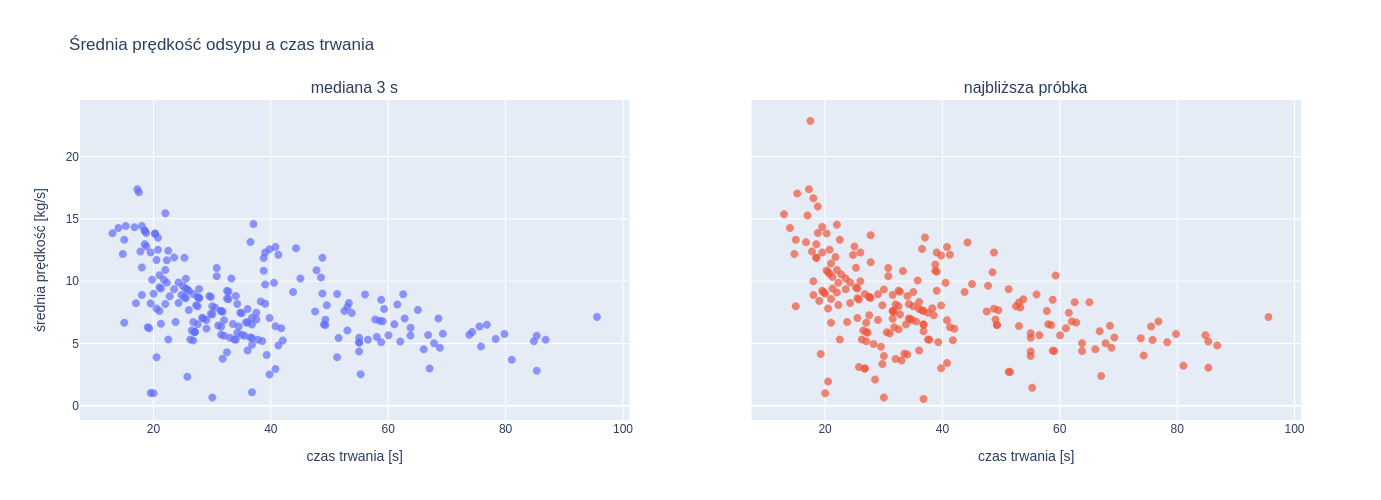

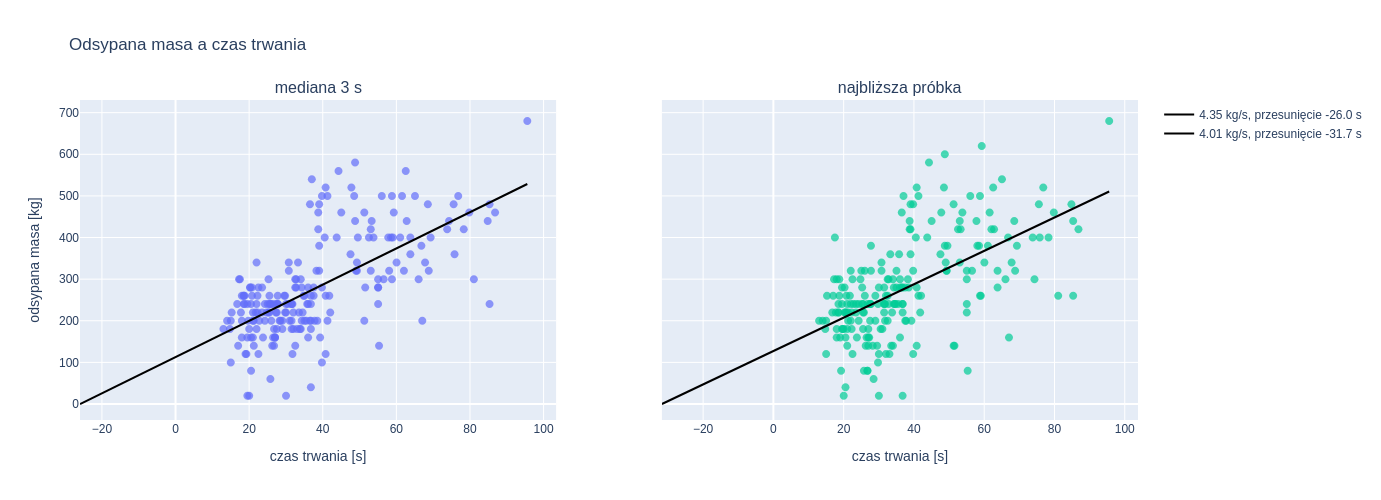

In [4]:
display(rate_figure(dispense, "Średnia prędkość odsypu a czas trwania", FIGURE_WIDTH))
display(mass_figure(dispense, "Odsypana masa a czas trwania", FIGURE_WIDTH))

## Wrażliwość na przycięcie

Te same miary dla każdej kombinacji przycięcia dołu i góry z `SENSITIVITY_LEVELS` (w procentach), liczone na odsypach po odrzuceniu różnic ≥ 0. Jeśli wnioski się nie zmieniają, nie trzeba wybierać poziomu przycięcia.

In [5]:
display(collapsible(trim_sensitivity(valid.kept, SENSITIVITY_LEVELS).round(3), "Wrażliwość na przycięcie", opened=True))